In [2]:
# RETAILVC RETAIL ANALYTICS
# PYTHON EXPLORATORY DATA ANALYSIS
# =====================================================

# 1. IMPORT LIBRARIES


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [9]:
# 2. LOAD DATASET

data = pd.read_csv("../data/marketing_campaign.csv")

In [10]:
data.head()


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,0,0,0,0,0,0,3,11,1,67
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,0,0,0,0,0,0,3,11,0,70
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,0,0,0,0,0,0,3,11,0,59
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,0,0,0,0,0,0,3,11,0,40
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,0,0,0,0,0,0,3,11,0,43


In [11]:
# 3. INSPECT DATASET
# ==========================================

print("Dataset Shape:", data.shape)

print("\nDataset Information:")
data.info()

print("\nMissing Values:")
print(data.isnull().sum())

Dataset Shape: (2240, 30)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 30 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int

In [12]:
# 4. CLEAN INCOME
# ==========================================

# Convert Income to numeric.
# Invalid/blank values become NaN.

data["Income"] = pd.to_numeric(
    data["Income"],
    errors="coerce"
)

print("\nMissing Income Before Imputation:")
print(data["Income"].isnull().sum())


Missing Income Before Imputation:
24


In [13]:
# 5. CONVERT CUSTOMER DATE
# ==========================================

data["Dt_Customer"] = pd.to_datetime(
    data["Dt_Customer"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("\nCustomer Date Type:")
print(data["Dt_Customer"].dtype)


Customer Date Type:
datetime64[ns]


In [15]:
 #6. INSPECT CATEGORICAL VARIABLES
# ==========================================

print("\nEducation Categories:")
print(data["Education"].value_counts())

print("\nMarital Status Categories:")
print(data["Marital_Status"].value_counts())


Education Categories:
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

Marital Status Categories:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


In [16]:
# 7. CLEAN MARITAL STATUS
# ==========================================

data["Marital_Status_Clean"] = data["Marital_Status"].replace({
    "Married": "Partner",
    "Together": "Partner",
    "Single": "Single",
    "Divorced": "Single",
    "Widow": "Single",
    "Alone": "Single",
    "Absurd": "Single",
    "YOLO": "Single"
})

print("\nCleaned Marital Status:")
print(data["Marital_Status_Clean"].value_counts())


Cleaned Marital Status:
Marital_Status_Clean
Partner    1444
Single      796
Name: count, dtype: int64


In [17]:
# ==========================================
# 8. IMPUTE MISSING INCOME
# ==========================================

# Fill missing Income using the average Income
# of customers with similar Education and
# Marital Status.

data["Income"] = data["Income"].fillna(
    data.groupby(
        ["Education", "Marital_Status"]
    )["Income"].transform("mean")
)

print("\nMissing Income After Imputation:")
print(data["Income"].isnull().sum())




Missing Income After Imputation:
0


In [18]:
# 9. CREATE AGE
# ==========================================

data["Calculated_Age"] = 2026 - data["Year_Birth"]

print(
    data[
        ["Year_Birth", "Calculated_Age"]
    ].head()
)


   Year_Birth  Calculated_Age
0        1957              69
1        1954              72
2        1965              61
3        1984              42
4        1981              45


In [19]:
# 10. CREATE TOTAL SPENDING
# ==========================================

data["Spending"] = (
    data["MntWines"]
    + data["MntFruits"]
    + data["MntMeatProducts"]
    + data["MntFishProducts"]
    + data["MntSweetProducts"]
    + data["MntGoldProds"]
)

print("\nTotal Spending:")
print(data[["ID", "Spending"]].head())




Total Spending:
     ID  Spending
0  5524      1617
1  2174        27
2  4141       776
3  6182        53
4  5324       422


In [20]:
# 11. CREATE CHILDREN COUNT
# ==========================================

data["Children_Count"] = (
    data["Kidhome"]
    + data["Teenhome"]
)

print(
    data[
        ["Kidhome", "Teenhome", "Children_Count"]
    ].head()
)


   Kidhome  Teenhome  Children_Count
0        0         0               0
1        1         1               2
2        0         0               0
3        1         0               1
4        1         0               1


In [21]:
# 12. CREATE HAS CHILDREN VARIABLE
# ==========================================

data["Has_Children"] = np.where(
    data["Children_Count"] > 0,
    1,
    0
)

print("\nHas Children:")
print(data["Has_Children"].value_counts())


Has Children:
Has_Children
1    1602
0     638
Name: count, dtype: int64


In [22]:
# 13. CREATE TOTAL PURCHASES
# ==========================================

data["Total_Purchases"] = (
    data["NumWebPurchases"]
    + data["NumCatalogPurchases"]
    + data["NumStorePurchases"]
)

print("\nTotal Purchases:")
print(data[["ID", "Total_Purchases"]].head())


Total Purchases:
     ID  Total_Purchases
0  5524               22
1  2174                4
2  4141               20
3  6182                6
4  5324               14


In [23]:
# 14. DESCRIPTIVE STATISTICS
# ==========================================

print("\nDescriptive Statistics:")

print(
    data[
        [
            "Income",
            "Spending",
            "Calculated_Age",
            "Total_Purchases"
        ]
    ].describe()
)




Descriptive Statistics:
              Income     Spending  Calculated_Age  Total_Purchases
count    2240.000000  2240.000000     2240.000000      2240.000000
mean    52248.748825   605.798214       57.194196        12.537054
std     25039.981052   602.249288       11.984069         7.205741
min      1730.000000     5.000000       30.000000         0.000000
25%     35538.750000    68.750000       49.000000         6.000000
50%     51381.500000   396.000000       56.000000        12.000000
75%     68289.750000  1045.500000       67.000000        18.000000
max    666666.000000  2525.000000      133.000000        32.000000


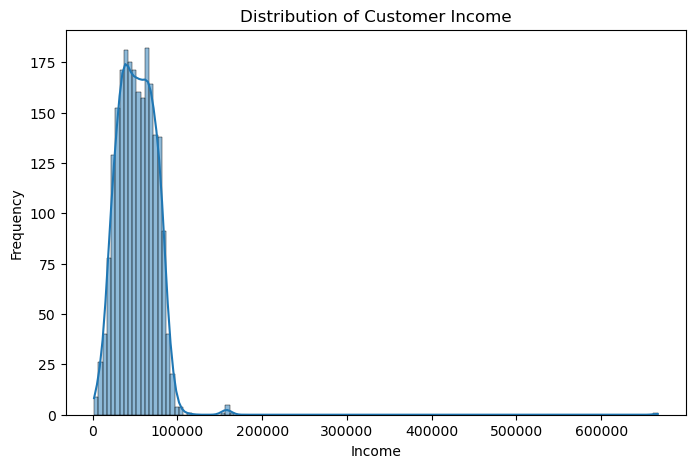

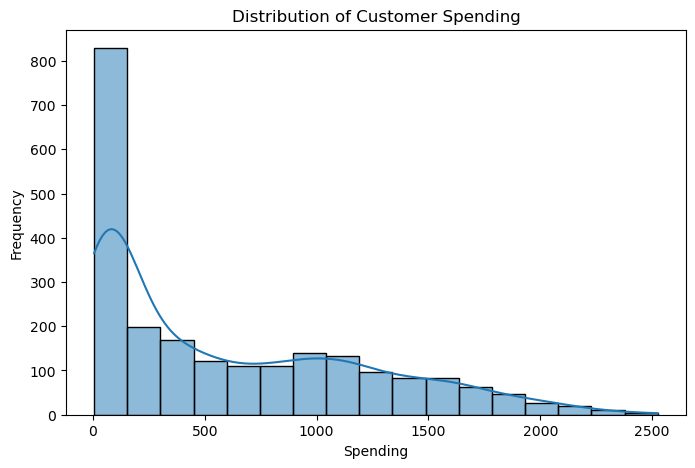

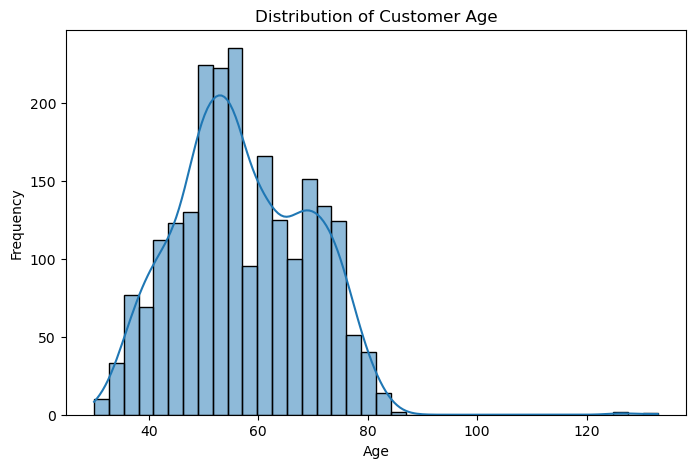

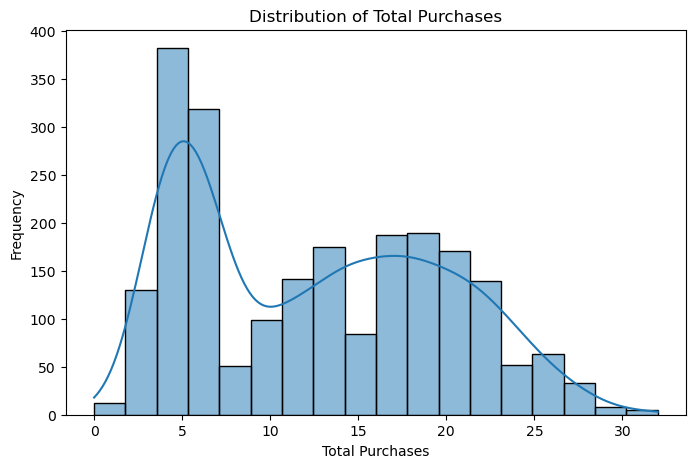

In [24]:
# 15. HISTOGRAMS
# ==========================================

# Income

plt.figure(figsize=(8, 5))
sns.histplot(data["Income"], kde=True)
plt.title("Distribution of Customer Income")
plt.xlabel("Income")
plt.ylabel("Frequency")
plt.show()


# Spending

plt.figure(figsize=(8, 5))
sns.histplot(data["Spending"], kde=True)
plt.title("Distribution of Customer Spending")
plt.xlabel("Spending")
plt.ylabel("Frequency")
plt.show()


# Age

plt.figure(figsize=(8, 5))
sns.histplot(data["Calculated_Age"], kde=True)
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# Total Purchases

plt.figure(figsize=(8, 5))
sns.histplot(data["Total_Purchases"], kde=True)
plt.title("Distribution of Total Purchases")
plt.xlabel("Total Purchases")
plt.ylabel("Frequency")
plt.show()


In [25]:
# 17. OUTLIER TREATMENT
# ==========================================

def cap_outliers(dataframe, column):

    q1 = dataframe[column].quantile(0.25)
    q3 = dataframe[column].quantile(0.75)

    iqr = q3 - q1

    lower_limit = q1 - (1.5 * iqr)
    upper_limit = q3 + (1.5 * iqr)

    dataframe[column] = dataframe[column].clip(
        lower=lower_limit,
        upper=upper_limit
    )


for column in [
    "Income",
    "Spending",
    "Calculated_Age",
    "Total_Purchases"
]:
    cap_outliers(data, column)


In [26]:
# 18. ORDINAL ENCODING - EDUCATION
# ==========================================

education_order = {
    "Basic": 0,
    "2n Cycle": 1,
    "Graduation": 2,
    "Master": 3,
    "PhD": 4
}

data["Education_Encoded"] = (
    data["Education"].map(education_order)
)

print(
    data[
        ["Education", "Education_Encoded"]
    ].head()
)



    Education  Education_Encoded
0  Graduation                  2
1  Graduation                  2
2  Graduation                  2
3  Graduation                  2
4         PhD                  4


In [27]:
# 19. ONE-HOT ENCODING - MARITAL STATUS
# ==========================================

data = pd.get_dummies(
    data,
    columns=["Marital_Status_Clean"],
    drop_first=True
)



In [28]:
# 20. CORRELATION MATRIX
# ==========================================

correlation_columns = [
    "Income",
    "Spending",
    "Calculated_Age",
    "Children_Count",
    "Total_Purchases",
    "NumWebVisitsMonth",
    "Response"
]

correlation_matrix = (
    data[correlation_columns].corr()
)

print("\nCorrelation Matrix:")
print(correlation_matrix)



Correlation Matrix:
                     Income  Spending  Calculated_Age  Children_Count  \
Income             1.000000  0.803737        0.204929       -0.345200   
Spending           0.803737  1.000000        0.113313       -0.498898   
Calculated_Age     0.204929  0.113313        1.000000        0.093232   
Children_Count    -0.345200 -0.498898        0.093232        1.000000   
Total_Purchases    0.754074  0.820734        0.168914       -0.379773   
NumWebVisitsMonth -0.648351 -0.500224       -0.120136        0.418419   
Response           0.166525  0.265280       -0.020058       -0.169163   

                   Total_Purchases  NumWebVisitsMonth  Response  
Income                    0.754074          -0.648351  0.166525  
Spending                  0.820734          -0.500224  0.265280  
Calculated_Age            0.168914          -0.120136 -0.020058  
Children_Count           -0.379773           0.418419 -0.169163  
Total_Purchases           1.000000          -0.425939  0.164688 

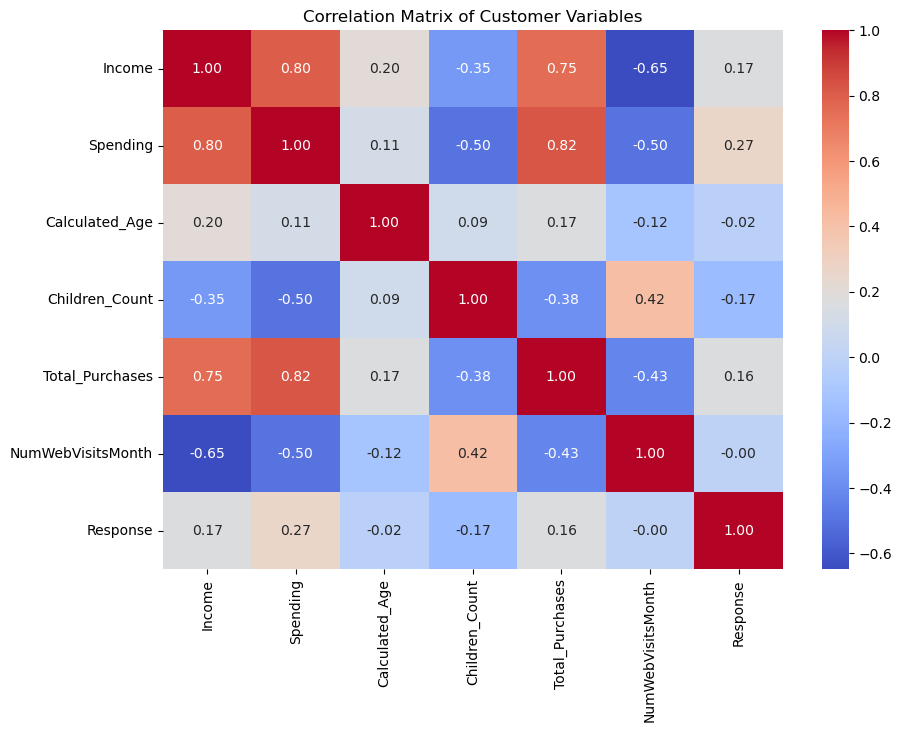

In [29]:
# 21. CORRELATION HEATMAP
# ==========================================

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title(
    "Correlation Matrix of Customer Variables"
)

plt.show()


In [30]:
# 22. HYPOTHESIS TEST
# RESPONDERS VS NON-RESPONDERS INCOME
# ==========================================

responders = data[
    data["Response"] == 1
]["Income"]

non_responders = data[
    data["Response"] == 0
]["Income"]

t_stat, p_value = stats.ttest_ind(
    responders,
    non_responders,
    equal_var=False
)

print("\nHypothesis Test Results:")
print("T-statistic:", t_stat)
print("P-value:", p_value)


Hypothesis Test Results:
T-statistic: 7.255467841873359
P-value: 1.9061682723078255e-12


In [31]:
# 23. HYPOTHESIS TEST CONCLUSION
# ==========================================

alpha = 0.05

if p_value < alpha:

    print("Reject the null hypothesis.")

    print(
        "There is a statistically significant "
        "difference in average income between "
        "responders and non-responders."
    )

else:

    print("Fail to reject the null hypothesis.")

    print(
        "There is insufficient evidence of a "
        "significant difference in average income "
        "between responders and non-responders."
    )

Reject the null hypothesis.
There is a statistically significant difference in average income between responders and non-responders.


In [32]:
# 24. FINAL DATA QUALITY CHECK
# ==========================================

print("\nFinal Data Quality Check")

print("Total Customers:", data.shape[0])

print(
    "Missing Income:",
    data["Income"].isnull().sum()
)

print(
    "Missing Customer Dates:",
    data["Dt_Customer"].isnull().sum()
)



Final Data Quality Check
Total Customers: 2240
Missing Income: 0
Missing Customer Dates: 0


In [34]:
 #25. FINAL DATASET PREVIEW
# ==========================================

print("\nFinal Dataset Preview:")

print(data.head())


Final Dataset Preview:
     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  Z_Revenue  Response  Age  \
0  2012-09-04       58       635  ...         11         1   67   
1  2014-03-08       38        11  ...         11         0   70   
2  2013-08-21       26       426  ...         11         0   59   
3  2014-02-10       26        11  ...         11         0   40   
4  2014-01-19       94       173  ...         11         0   43   

   Calculated_Age  Spending  Children_Count  Has_Children  Total_Purchases  \
0              69    1617.